# Data Exploration

In [1]:
import pandas as pd
import numpy as np
import random
random.seed(0)
import matplotlib.pyplot as plt
import os
from PIL import Image
from torchvision import io

In [2]:
df = pd.read_csv("../mini_imagenet/coeffs.csv")
print(df.info())
# print(df.describe())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32825 entries, 0 to 32824
Data columns (total 18 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   path    32825 non-null  object 
 1   100     32825 non-null  float64
 2   125     32825 non-null  float64
 3   160     32825 non-null  float64
 4   200     32825 non-null  float64
 5   250     32825 non-null  float64
 6   315     32825 non-null  float64
 7   400     32825 non-null  float64
 8   500     32825 non-null  float64
 9   630     32825 non-null  float64
 10  800     32825 non-null  float64
 11  1000    32825 non-null  float64
 12  1250    32825 non-null  float64
 13  1600    32825 non-null  float64
 14  2000    32825 non-null  float64
 15  2500    32825 non-null  float64
 16  3150    32825 non-null  float64
 17  4000    32825 non-null  float64
dtypes: float64(17), object(1)
memory usage: 4.5+ MB
None


,path,100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000
0,n01532829/n01532829_3649.JPEG,0.752701,0.743908,0.729484,0.712731,0.695864,0.686575,0.673583,0.567384,0.424873,0.439902,0.452475,0.374287,0.264912,0.201245,0.143370,0.119635,0.148737
1,n01532829/n01532829_82.JPEG,0.746089,0.735882,0.719416,0.699414,0.676045,0.652699,0.619675,0.525425,0.393852,0.334975,0.274404,0.225264,0.163362,0.141593,0.167942,0.172648,0.145125
2,n01532829/n01532829_14005.JPEG,0.748687,0.738679,0.722617,0.703265,0.680915,0.658819,0.624923,0.529340,0.408224,0.380325,0.334280,0.284943,0.195678,0.151803,0.149029,0.126490,0.109870
3,n01532829/n01532829_4237.JPEG,0.738166,0.728378,0.712761,0.693872,0.671811,0.649669,0.616652,0.520248,0.389083,0.346235,0.306368,0.286319,0.240484,0.240037,0.238294,0.211064,0.280647
4,n01532829/n01532829_3281.JPEG,0.760439,0.752280,0.737050,0.717789,0.695589,0.674879,0.642875,0.538306,0.392633,0.348146,0.274171,0.224052,0.197637,0.136487,0.165408,0.110638,0.067479


In [3]:
# statistics of diffusion coefficients by frequency
coeffs = df.drop(columns=["path"])
df.describe()

,100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000
count,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000
mean,0.732642,0.723184,0.708461,0.691068,0.671623,0.654524,0.627891,0.531378,0.416283,0.388711,0.345826,0.307867,0.260050,0.207335,0.187919,0.182637,0.174357
std,0.017481,0.017903,0.018424,0.019634,0.023314,0.033306,0.044994,0.033487,0.037771,0.072885,0.095405,0.097749,0.086943,0.076603,0.076240,0.082017,0.084637
min,0.616302,0.628035,0.626267,0.595196,0.522643,0.441061,0.415551,0.368628,0.312482,0.189622,0.173093,0.117289,0.079012,0.050600,0.032486,0.020281,0.013658
25%,0.726306,0.716494,0.700986,0.682043,0.659033,0.633714,0.596355,0.509535,0.391835,0.336407,0.271902,0.227829,0.192824,0.148747,0.131661,0.121550,0.111250
50%,0.735249,0.725626,0.710588,0.692804,0.672679,0.654087,0.623506,0.524749,0.406769,0.368090,0.323001,0.294716,0.250681,0.195140,0.175091,0.169228,0.160941
75%,0.742659,0.733254,0.718769,0.702297,0.685577,0.675133,0.654728,0.545584,0.429414,0.421824,0.405146,0.377829,0.318164,0.252681,0.231436,0.231034,0.223881
max,0.855422,0.862471,0.867262,0.889296,0.906692,0.893285,0.858118,0.762297,0.763309,0.773371,0.741448,0.745612,0.657054,0.683782,0.633739,0.600147,0.593958


In [4]:
# how to fetch coefficients by path
df.loc[df["path"]=="n01532829/n01532829_14005.JPEG",:].drop(columns="path").to_numpy()[0]

array([0.7486874 , 0.73867861, 0.72261677, 0.70326459, 0.68091461,
       0.65881937, 0.62492271, 0.52933969, 0.40822443, 0.38032542,
       0.33428029, 0.28494318, 0.19567755, 0.1518028 , 0.14902901,
       0.12649009, 0.10986964])

In [5]:
# create dataframe of all image paths
paths = df[["path"]]
print(paths.nunique())
paths.head()

path    32825
dtype: int64


,path
0,n01532829/n01532829_3649.JPEG
1,n01532829/n01532829_82.JPEG
2,n01532829/n01532829_14005.JPEG
3,n01532829/n01532829_4237.JPEG
4,n01532829/n01532829_3281.JPEG


## How many images have been processed

In [6]:
test_path = "n01532829/n01532829_3649.JPEG"
file = test_path.split("/")[1]
file

'n01532829_3649.JPEG'

In [7]:
# split image paths into elements
paths.loc[:,"directory"] = paths.path.map(lambda path: path.split("/")[0])
paths.loc[:,"file"] = paths.path.map(lambda path: path.split("/")[1])
paths.loc[:,"file"] = paths.file.map(lambda path: path.split(".")[0])
paths.loc[:,"file_id"] = paths.file.map(lambda path: path.split("_")[1])
paths.head()

/tmp/ipykernel_2853222/3696402881.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths.loc[:,"directory"] = paths.path.map(lambda path: path.split("/")[0])
/tmp/ipykernel_2853222/3696402881.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths.loc[:,"file"] = paths.path.map(lambda path: path.split("/")[1])
/tmp/ipykernel_2853222/3696402881.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See th

,path,directory,file,file_id
0,n01532829/n01532829_3649.JPEG,n01532829,n01532829_3649,3649
1,n01532829/n01532829_82.JPEG,n01532829,n01532829_82,82
2,n01532829/n01532829_14005.JPEG,n01532829,n01532829_14005,14005
3,n01532829/n01532829_4237.JPEG,n01532829,n01532829_4237,4237
4,n01532829/n01532829_3281.JPEG,n01532829,n01532829_3281,3281


In [8]:
# count number of processed images per directory/category
num_img_per_dir = paths.groupby(["directory"])[["file"]].count()
print(num_img_per_dir.describe()) 
num_img_per_dir.sample(7)

             file
count  100.000000
mean   328.250000
std    106.971475
min     26.000000
25%    284.000000
50%    321.000000
75%    389.000000
max    600.000000


,file
directory,
n03838899,274
n07747607,385
n04604644,244
n03773504,338
n03676483,337
n02165456,319
n04443257,533


## Image Sizes

In [9]:
# make DataFrame with image dimensions for ALL images
data_dir = "../mini_imagenet/"

sizes_all = []

for root, _, fnames in sorted(os.walk(data_dir, followlinks=True)):
    for fname in sorted(fnames):
        path = os.path.join(root, fname)
        
        if fname.lower().endswith(('.jpeg', '.jpg')):
            image = Image.open(path)
            image = image.convert("RGB")
            img_size = image.size
            sizes_all.append([fname, img_size[0], img_size[1], img_size[0]*img_size[1]])
            
sizes_all = pd.DataFrame(sizes_all, columns=["path", "x", "y", "total"])
sizes_all.head()

,path,x,y,total
0,n01532829_10006.JPEG,357,500,178500
1,n01532829_10032.JPEG,640,512,327680
2,n01532829_10104.JPEG,500,480,240000
3,n01532829_10127.JPEG,500,375,187500
4,n01532829_1017.JPEG,500,361,180500


In [10]:
# image size stats
sizes_all.describe()

,x,y,total
count,60000.000000,60000.000000,6.000000e+04
mean,469.430867,407.342333,2.224888e+05
std,217.817172,191.355786,4.187828e+05
min,8.000000,32.000000,4.800000e+02
25%,375.000000,333.000000,1.665000e+05
50%,500.000000,375.000000,1.875000e+05
75%,500.000000,500.000000,1.875000e+05
max,4768.000000,5980.000000,2.851264e+07


In [11]:
# make DataFrame with image dimensions for PROCESSED images
data_dir = "../mini_imagenet/"

sizes = []


for path in df.path:
    image = Image.open(data_dir+path)
    image = image.convert("RGB")
    img_size = image.size
    sizes.append([path, img_size[0], img_size[1], img_size[0]*img_size[1]])

sizes = pd.DataFrame(sizes, columns=["path", "x", "y", "total"])
sizes.head()

,path,x,y,total
0,n01532829/n01532829_3649.JPEG,500,417,208500
1,n01532829/n01532829_82.JPEG,396,500,198000
2,n01532829/n01532829_14005.JPEG,500,386,193000
3,n01532829/n01532829_4237.JPEG,367,334,122578
4,n01532829/n01532829_3281.JPEG,491,500,245500


In [12]:
# image size stats
sizes.describe()

,x,y,total
count,32825.000000,32825.000000,3.282500e+04
mean,469.226870,407.318903,2.194262e+05
std,210.179691,182.687269,3.564914e+05
min,14.000000,32.000000,1.650000e+03
25%,375.000000,333.000000,1.665000e+05
50%,500.000000,375.000000,1.875000e+05
75%,500.000000,500.000000,1.875000e+05
max,3528.000000,3456.000000,8.438976e+06


In [13]:
def center_crop(img):
    """
    Crops the input image to a central square of maximum possible size
    """
    h, w = img.shape[1:]
    min_dim = min(h, w)
    top = (h - min_dim) // 2
    left = (w - min_dim) // 2
    # print(f"min_dim: {min_dim}, top: {top}, bottom: {top+min_dim}, left: {left}, right: {left+min_dim}")
    return img[:, top:top+min_dim, left:left+min_dim]

In [14]:
# make DataFrame with image dimensions for all images after center cropping
cropped_sizes_all = []

for root, _, fnames in sorted(os.walk(data_dir, followlinks=True)):
    for fname in sorted(fnames):
        path = os.path.join(root, fname)
        
        if fname.lower().endswith(('.jpeg', '.jpg')):
            image = io.decode_image(path, mode=io.ImageReadMode.RGB)
            # print("----------------------------")
            # print(f"Before: {list(image.shape)}")
            cropped_img = center_crop(image)
            if cropped_img.shape[1]!= cropped_img.shape[2]:
                print(f"Before: {list(image.shape)}")
                print(f"After: {list(cropped_img.shape)}")
            cropped_sizes_all.append([fname, cropped_img.shape[1], cropped_img.shape[2]])

cropped_sizes_all = pd.DataFrame(cropped_sizes_all, columns=["path", "h", "w"])
cropped_sizes_all.head()

,path,h,w
0,n01532829_10006.JPEG,357,357
1,n01532829_10032.JPEG,512,512
2,n01532829_10104.JPEG,480,480
3,n01532829_10127.JPEG,375,375
4,n01532829_1017.JPEG,361,361


In [15]:
# cropped image size stats
cropped_sizes_all.describe()

,h,w
count,60000.000000,60000.000000
mean,370.704633,370.704633
std,164.560855,164.560855
min,8.000000,8.000000
25%,333.000000,333.000000
50%,375.000000,375.000000
75%,375.000000,375.000000
max,4768.000000,4768.000000


In [16]:
print(f"Number of landscape format images: {np.sum((sizes.x > sizes.y))}")
print(f"Number of portrait format images: {np.sum((sizes.x < sizes.y))}")
print(f"Number of suqare images: {np.sum((sizes.x == sizes.y))}")

Number of landscape format images: 22885
Number of portrait format images: 8943
Number of suqare images: 997


In [17]:
# print(f"Median x: {np.median(sizes.x)}") # -> 500
# print(f"Median y: {np.median(sizes.y)}") # -> 300
# print(f"Median x: {np.median(sizes_all.x)}") # -> 500
# print(f"Median y: {np.median(sizes_all.y)}") # -> 300
print(f"Median h: {np.median(cropped_sizes_all.h)}") # -> 375
print(f"Median w: {np.median(cropped_sizes_all.w)}") # -> 375

Median h: 375.0
Median w: 375.0


In [18]:
def transform(totals: np.ndarray):
    """
    transforms total number of pixels in an image (totals) to achieve a more helpful colormap.
    """
    # return totals
    return (totals)**(1/4)
    # return 100*np.log(totals)

Text(0.5, 1.0, 'All images')

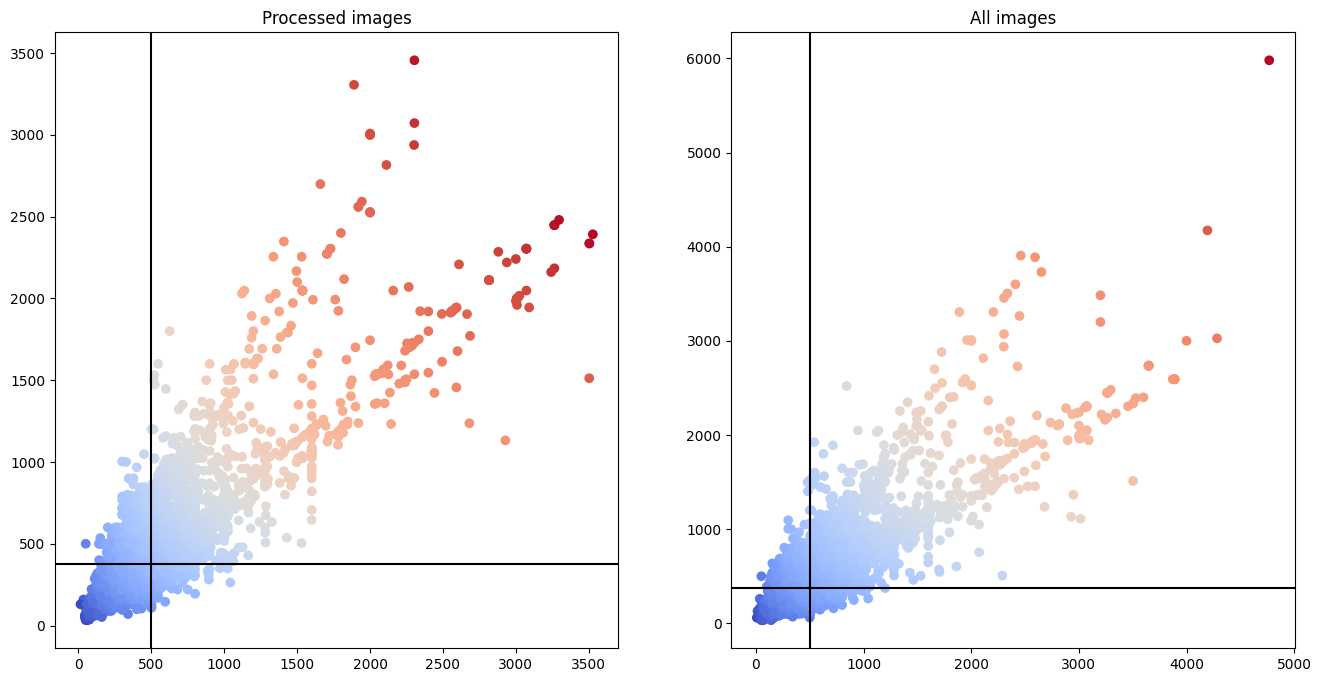

In [19]:
# plot image dimensions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8))

ax1.scatter(sizes.x.to_numpy(), sizes.y.to_numpy(), c=transform(sizes.total.to_numpy()), cmap='coolwarm')
pos = ax2.scatter(sizes_all.x.to_numpy(), sizes_all.y.to_numpy(), c=transform(sizes_all.total.to_numpy()), cmap='coolwarm')
ax1.axvline(x=500, c='k')
ax1.axhline(y=375, c='k')
ax2.axvline(x=500, c='k')
ax2.axhline(y=375, c='k')

# ax1.set_xscale('log')
# ax1.set_yscale('log')
# ax2.set_xscale('log')
# ax2.set_yscale('log')

# fig.colorbar(pos, ax=ax2)

ax1.set_title("Processed images")
ax2.set_title("All images")

## Train/Test/Val Split

In [20]:
train_ratio = 0.7
val_ratio = 0.1
test_ratio = 1-train_ratio-val_ratio

In [21]:
pth = list(set(df['path'].tolist()))

In [22]:
# how to round to integers
l = len(pth)
# l += 0
train_len = l*train_ratio
val_len = l*val_ratio
test_len = l*test_ratio
print(f"train: {train_len} -> {int(train_len)} or {np.round(train_len)}")
print(f"val: {val_len} -> {int(val_len)} or {np.round(val_len)}")
print(f"test: {test_len} -> {int(test_len)} or {np.round(test_len)}")
print(f"total: {train_len+val_len +test_len} -> {int(train_len)+int(val_len)+int(test_len)} or {np.round(train_len)+np.round(val_len)+np.round(test_len)}")

train: 22977.5 -> 22977 or 22978.0
val: 3282.5 -> 3282 or 3282.0
test: 6565.000000000001 -> 6565 or 6565.0
total: 32825.0 -> 32824 or 32825.0


In [23]:
# split into train/val/test
random.shuffle(pth)
train_paths = pth[:int(len(pth)*train_ratio)]
val_paths = pth[int(len(pth)*train_ratio): int(len(pth)*(train_ratio+val_ratio))]
test_paths = pth[int(len(pth)*(train_ratio+val_ratio)):]


In [24]:
# add datasplit column to paths dataframe
paths.loc[paths["path"].isin(train_paths),"datasplit"] = "train"
paths.loc[paths["path"].isin(val_paths),"datasplit"] = "val"
paths.loc[paths["path"].isin(test_paths),"datasplit"] = "test"
paths.sample(5)

/tmp/ipykernel_2853222/36479648.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths.loc[paths["path"].isin(train_paths),"datasplit"] = "train"


,path,directory,file,file_id,datasplit
20658,n03544143/n03544143_15572.JPEG,n03544143,n03544143_15572,15572,train
6710,n04522168/n04522168_7863.JPEG,n04522168,n04522168_7863,7863,test
9071,n02113712/n02113712_1066.JPEG,n02113712,n02113712_1066,1066,train
12663,n09246464/n09246464_20204.JPEG,n09246464,n09246464_20204,20204,test
15334,n13054560/n13054560_10490.JPEG,n13054560,n13054560_10490,10490,train


In [25]:
# encode datasplit with onehot encoding
paths.loc[paths["path"].isin(train_paths),"train"] = 1
paths.loc[paths["path"].isin(val_paths),"val"] = 1
paths.loc[paths["path"].isin(test_paths),"test"] = 1
paths.fillna(0, inplace=True)
paths.sample(7)

/tmp/ipykernel_2853222/767263264.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths.loc[paths["path"].isin(train_paths),"train"] = 1
/tmp/ipykernel_2853222/767263264.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paths.loc[paths["path"].isin(val_paths),"val"] = 1
/tmp/ipykernel_2853222/767263264.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pa

,path,directory,file,file_id,datasplit,train,val,test
5765,n02971356/n02971356_324.JPEG,n02971356,n02971356_324,324,train,1.0,0.0,0.0
5781,n01981276/n01981276_18424.JPEG,n01981276,n01981276_18424,18424,train,1.0,0.0,0.0
31011,n02108551/n02108551_2698.JPEG,n02108551,n02108551_2698,2698,train,1.0,0.0,0.0
21434,n02138441/n02138441_6679.JPEG,n02138441,n02138441_6679,6679,test,0.0,0.0,1.0
3921,n02457408/n02457408_4117.JPEG,n02457408,n02457408_4117,4117,train,1.0,0.0,0.0
18172,n02795169/n02795169_31608.JPEG,n02795169,n02795169_31608,31608,train,1.0,0.0,0.0
16211,n03075370/n03075370_8115.JPEG,n03075370,n03075370_8115,8115,train,1.0,0.0,0.0


In [26]:
# count how many images in train/val/test per image directory
split_counts = paths.groupby(["directory"])[["train", "val", "test"]].sum().reset_index()
print(split_counts.describe()) 
split_counts.sample(7)

            train         val        test
count  100.000000  100.000000  100.000000
mean   229.770000   32.820000   65.660000
std     75.146302   12.231257   22.591328
min     15.000000    2.000000    9.000000
25%    196.750000   25.000000   55.000000
50%    225.500000   32.000000   64.000000
75%    273.250000   41.000000   76.500000
max    401.000000   64.000000  135.000000


,directory,train,val,test
32,n02443484,243.0,21.0,67.0
63,n03770439,257.0,30.0,75.0
77,n04251144,319.0,45.0,84.0
54,n03347037,120.0,20.0,45.0
12,n02091244,239.0,27.0,60.0
59,n03535780,277.0,46.0,84.0
7,n01910747,127.0,22.0,44.0


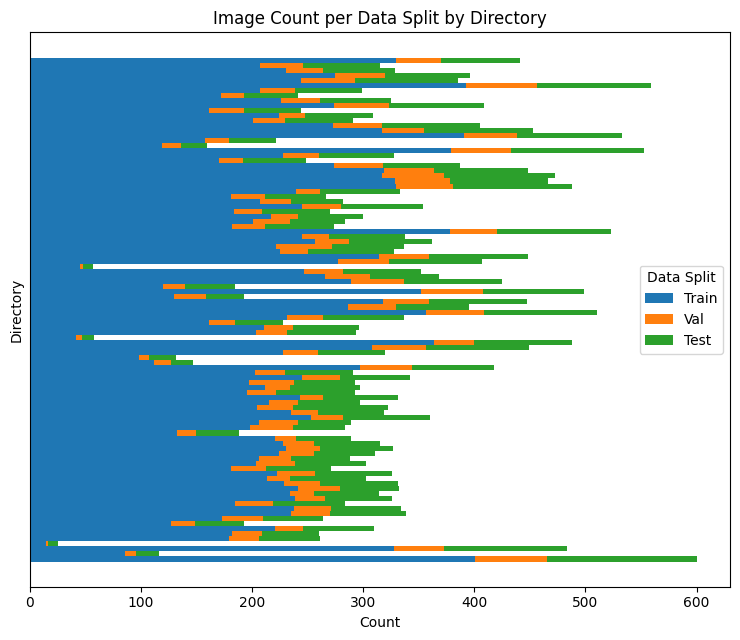

In [27]:
# plot image count per datasplit by directory
plt.rcParams["figure.figsize"] = [7.50, 6.50]
plt.rcParams["figure.autolayout"] = True

directories = split_counts.directory.to_list()
train =split_counts.train.to_numpy()
val = split_counts.val.to_numpy()
test = split_counts.test.to_numpy()

b1 = plt.barh(directories, train, height=1.0)
b2 = plt.barh(directories, val, left=train, height=1.0)
b3 = plt.barh(directories, test, left=val+train, height=1.0)

plt.legend([b1, b2, b3], ["Train", "Val", "Test"], title="Data Split")
plt.yticks([])
plt.title("Image Count per Data Split by Directory")
plt.ylabel("Directory")
plt.xlabel("Count")

plt.show()

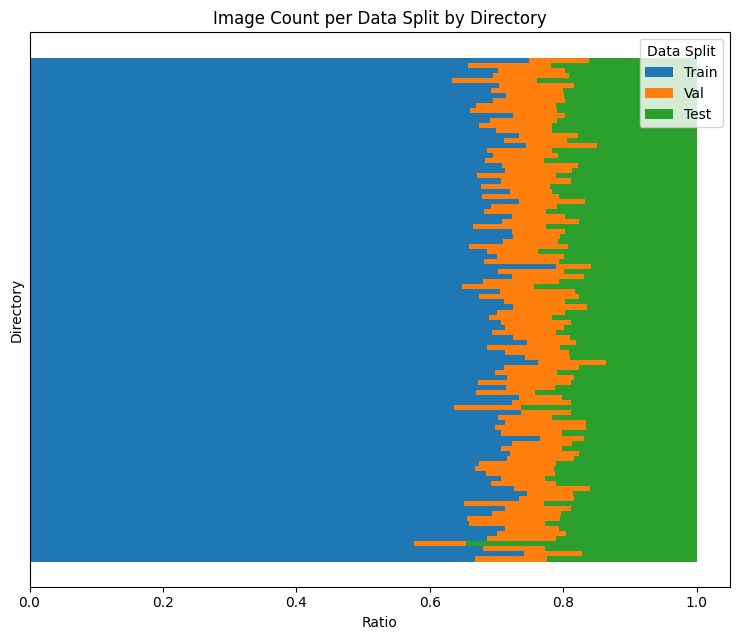

In [28]:
# plot image count per datasplit by directory in percent
plt.rcParams["figure.figsize"] = [7.50, 6.50]
plt.rcParams["figure.autolayout"] = True


train_perc = train/(train+val+test)
val_perc = val/(train+val+test)
test_perc = test/(train+val+test)


b1 = plt.barh(directories, train_perc, height=1.0)
b2 = plt.barh(directories, val_perc, left=train_perc, height=1.0)
b3 = plt.barh(directories, test_perc, left=val_perc+train_perc, height=1.0)

plt.legend([b1, b2, b3], ["Train", "Val", "Test"], title="Data Split")
plt.yticks([])
plt.title("Image Count per Data Split by Directory")
plt.ylabel("Directory")
plt.xlabel("Ratio")

plt.show()

In [29]:
# dataframe with percentages of each dataframe per directory
percentages = split_counts[["train", "val", "test"]].div(split_counts[["train", "val", "test"]].sum(axis=1), axis=0)

# Add back the 'directory' column
percentages["directory"] = split_counts["directory"]
percentages.head()

,train,val,test,directory
0,0.668333,0.106667,0.225000,n01532829
1,0.741379,0.086207,0.172414,n01558993
2,0.679089,0.093168,0.227743,n01704323
3,0.576923,0.076923,0.346154,n01749939
4,0.685824,0.103448,0.210728,n01770081


In [30]:
# sort DF by percentage of a split
percentages.sort_values("test", axis=0, ascending=False, inplace=True)
# percentages.sort_values("train", axis=0, ascending=True, inplace=True)

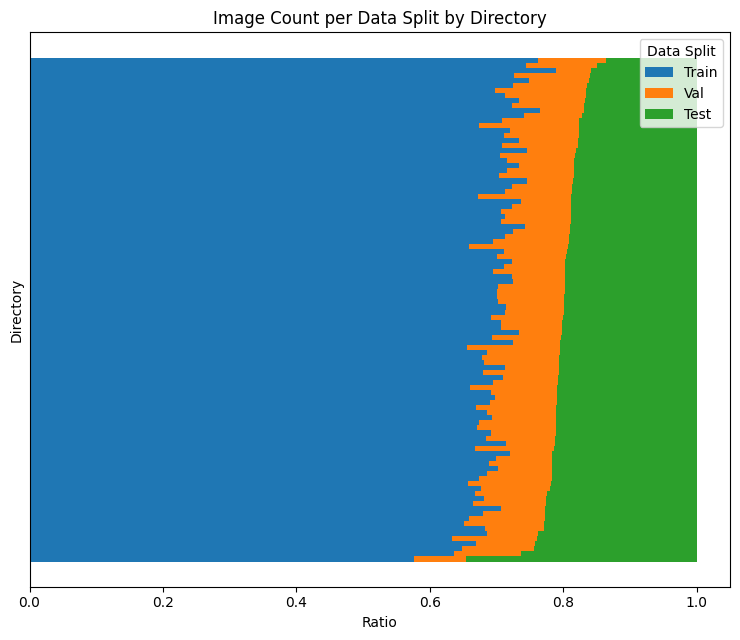

In [31]:
# plot image count per datasplit by directory in percent sorted by test percentage
plt.rcParams["figure.figsize"] = [7.50, 6.50]
plt.rcParams["figure.autolayout"] = True

dir = percentages.directory.to_list()
train_perc = percentages.train.to_numpy()
val_perc = percentages.val.to_numpy()
test_perc = percentages.test.to_numpy()


b1 = plt.barh(dir, train_perc, height=1.0)
b2 = plt.barh(dir, val_perc, left=train_perc, height=1.0)
b3 = plt.barh(dir, test_perc, left=val_perc+train_perc, height=1.0)

plt.legend([b1, b2, b3], ["Train", "Val", "Test"], title="Data Split")
plt.yticks([])
plt.title("Image Count per Data Split by Directory")
plt.ylabel("Directory")
plt.xlabel("Ratio")

plt.show()

### Save splits to .txt

In [32]:
with open(r'train_paths.txt', 'w') as fp:
    for path in train_paths:
        # write each item on a new line
        fp.write("%s\n" % path)
with open(r'val_paths.txt', 'w') as fp:
    for path in val_paths:
        # write each item on a new line
        fp.write("%s\n" % path)
with open(r'test_paths.txt', 'w') as fp:
    for path in test_paths:
        # write each item on a new line
        fp.write("%s\n" % path)
print('Done')

Done


## Target Normalization

In [33]:
# diffusion coefficient stats
coeffs = df.drop(columns=["path"])
coeffs.describe()

,100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000
count,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000,32825.000000
mean,0.732642,0.723184,0.708461,0.691068,0.671623,0.654524,0.627891,0.531378,0.416283,0.388711,0.345826,0.307867,0.260050,0.207335,0.187919,0.182637,0.174357
std,0.017481,0.017903,0.018424,0.019634,0.023314,0.033306,0.044994,0.033487,0.037771,0.072885,0.095405,0.097749,0.086943,0.076603,0.076240,0.082017,0.084637
min,0.616302,0.628035,0.626267,0.595196,0.522643,0.441061,0.415551,0.368628,0.312482,0.189622,0.173093,0.117289,0.079012,0.050600,0.032486,0.020281,0.013658
25%,0.726306,0.716494,0.700986,0.682043,0.659033,0.633714,0.596355,0.509535,0.391835,0.336407,0.271902,0.227829,0.192824,0.148747,0.131661,0.121550,0.111250
50%,0.735249,0.725626,0.710588,0.692804,0.672679,0.654087,0.623506,0.524749,0.406769,0.368090,0.323001,0.294716,0.250681,0.195140,0.175091,0.169228,0.160941
75%,0.742659,0.733254,0.718769,0.702297,0.685577,0.675133,0.654728,0.545584,0.429414,0.421824,0.405146,0.377829,0.318164,0.252681,0.231436,0.231034,0.223881
max,0.855422,0.862471,0.867262,0.889296,0.906692,0.893285,0.858118,0.762297,0.763309,0.773371,0.741448,0.745612,0.657054,0.683782,0.633739,0.600147,0.593958


In [34]:
# compute mean and std of coefficients by frequency
means = coeffs.mean().to_numpy()
stds = coeffs.std().to_numpy()
print(f"Mean:\n{means}")
print(f"Standard deviation:\n{stds}")

Mean:
[0.73264203 0.72318366 0.70846143 0.69106804 0.67162337 0.65452368
 0.62789064 0.53137842 0.41628288 0.38871101 0.34582556 0.30786727
 0.26005021 0.207335   0.18791921 0.1826369  0.1743572 ]
Standard deviation:
[0.01748138 0.01790273 0.01842413 0.01963412 0.02331358 0.03330641
 0.04499403 0.03348732 0.03777089 0.07288522 0.09540481 0.0977488
 0.08694257 0.07660307 0.07623988 0.08201716 0.08463709]


In [35]:
# normalize coefficients by mean and std
normalized_coeffs = (coeffs - means) / stds
normalized_coeffs.describe()

,100,125,160,200,250,315,400,500,630,800,1000,1250,1600,2000,2500,3150,4000
count,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04,3.282500e+04
mean,2.277200e-16,6.424648e-16,7.299163e-16,-1.297918e-15,2.193645e-15,-2.486088e-15,1.570662e-15,-1.473686e-15,1.260686e-15,3.519703e-16,2.078053e-16,6.060989e-18,-3.225312e-16,-1.692748e-16,5.260073e-17,1.065002e-16,7.359772e-18
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-6.655082e+00,-5.314751e+00,-4.461253e+00,-4.882944e+00,-6.390263e+00,-6.409050e+00,-4.719275e+00,-4.860058e+00,-2.748167e+00,-2.731545e+00,-1.810525e+00,-1.949677e+00,-2.082274e+00,-2.046069e+00,-2.038739e+00,-1.979533e+00,-1.898691e+00
25%,-3.624343e-01,-3.736436e-01,-4.057150e-01,-4.596438e-01,-5.400286e-01,-6.247806e-01,-7.008814e-01,-6.522924e-01,-6.472791e-01,-7.176261e-01,-7.748417e-01,-8.188151e-01,-7.732237e-01,-7.648237e-01,-7.379070e-01,-7.448103e-01,-7.456224e-01
50%,1.491325e-01,1.364071e-01,1.154050e-01,8.839298e-02,4.529646e-02,-1.309917e-02,-9.744127e-02,-1.979727e-01,-2.518797e-01,-2.829266e-01,-2.392427e-01,-1.345457e-01,-1.077668e-01,-1.591966e-01,-1.682587e-01,-1.634920e-01,-1.585147e-01
75%,5.729896e-01,5.625060e-01,5.594402e-01,5.718981e-01,5.985347e-01,6.187929e-01,5.964596e-01,4.242174e-01,3.476472e-01,4.543215e-01,6.217784e-01,7.157283e-01,6.684113e-01,5.919649e-01,5.707935e-01,5.900906e-01,5.851364e-01
max,7.023445e+00,7.780231e+00,8.619181e+00,1.009611e+01,1.008290e+01,7.168628e+00,5.116842e+00,6.895699e+00,9.187659e+00,5.277619e+00,4.146780e+00,4.478259e+00,4.566282e+00,6.219683e+00,5.847597e+00,5.090521e+00,4.957645e+00


<Axes: >

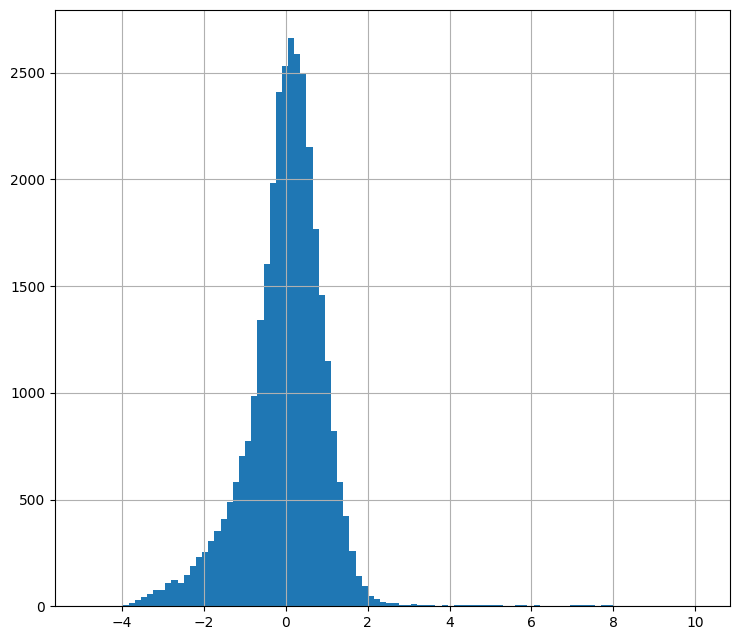

In [36]:
# plot distribution of normalized coefficients at frequency 200
normalized_coeffs['200'].hist(bins=100)

## Pressure Data

In [37]:
# shape of pressure data?
sample = np.load('n01532829_124.npy')
sample.shape

(17, 32768)

In [38]:
# what do pressures look like?
sample[0]

array([ 1.22454606e-07-7.16454892e-08j, -1.33232108e-07-6.01237619e-08j,
        5.04966802e-08+1.41838302e-07j, ...,
       -1.81812962e-07+3.29674593e-07j,  1.65013785e-07-3.23994538e-07j,
       -9.77078107e-08+3.36992252e-07j], shape=(32768,))

In [39]:
print(f"Min: {np.abs(sample).min()}, Max: {np.abs(sample).max()}")


Min: 3.5819930182240173e-09, Max: 0.0001414363224289466


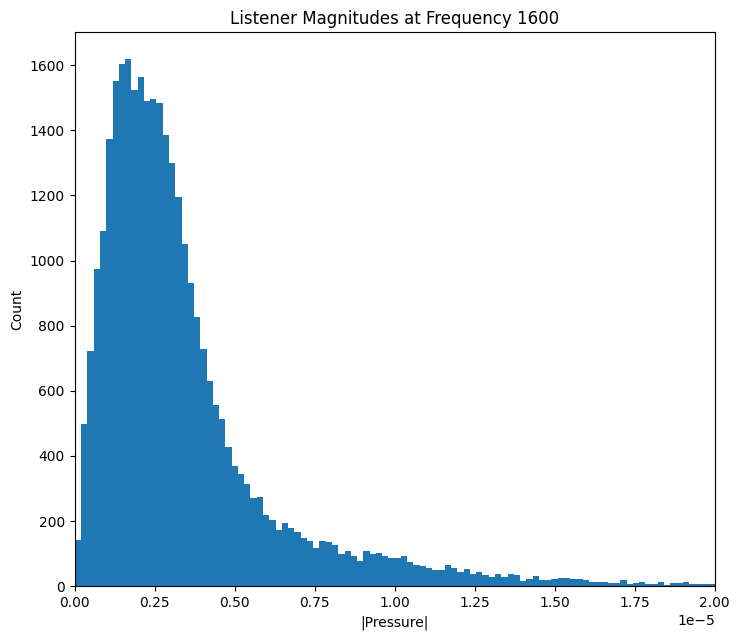

In [40]:
ALL_FREQ_BANDS = [100, 125, 160, 200, 250, 315, 400, 500, 630, 800, 1000, 1250, 1600, 2000, 2500, 3150, 4000]
idx = 12
plt.hist(np.abs(sample[idx].flatten()), bins=500)
plt.title(f"Listener Magnitudes at Frequency {ALL_FREQ_BANDS[idx]}")
plt.xlabel("|Pressure|")
# plt.xscale("log")
plt.xlim(0,2e-5)
plt.ylabel("Count")
plt.show()

In [41]:
# how to get back 3D shape?
shaped = sample.reshape(sample.shape[0], 32,32,32)
shaped.shape

(17, 32, 32, 32)

In [42]:
# how to get back flattened pressures
flat = shaped.reshape(sample.shape[0], -1)
flat.shape[1]

32768

### Grid function

In [43]:
def generate_3d_grid(n, x_range=(0, 1), y_range=(0, 1), z_range=(0, 1)):
    x = np.linspace(x_range[0], x_range[1], n)
    y = np.linspace(y_range[0], y_range[1], n)
    z = np.linspace(z_range[0], z_range[1], n)

    X, Y, Z = np.meshgrid(x, y, z, indexing='ij')  # shape (n, n, n)
    grid = np.stack((X, Y, Z), axis=-1)            # shape (n, n, n, 3)

    return grid.reshape(-1, 3)  # Flatten to (n**3, 3)

generate_3d_grid(32, x_range=(-50, 50), y_range=(0.07, 50), z_range=(-50, 50))

array([[-50.        ,   0.07      , -50.        ],
       [-50.        ,   0.07      , -46.77419355],
       [-50.        ,   0.07      , -43.5483871 ],
       ...,
       [ 50.        ,  50.        ,  43.5483871 ],
       [ 50.        ,  50.        ,  46.77419355],
       [ 50.        ,  50.        ,  50.        ]], shape=(32768, 3))

In [44]:
# splitting grid function into steps
n = 2
x_range = [-5, 5]
y_range = [0, 10]
z_range = [-20, 20]
x = np.linspace(x_range[0], x_range[1], n)
y = np.linspace(y_range[0], y_range[1], n)
z = np.linspace(z_range[0], z_range[1], n)
print(x)
print(y)
print(z)

[-5.  5.]
[ 0. 10.]
[-20.  20.]


In [45]:
X, Y, Z = np.meshgrid(x, y, z, indexing='ij')  # shape (n, n, n)
print(X)
print("-----------")
print(Y)
print("-----------")
print(Z)

[[[-5. -5.]
  [-5. -5.]]

 [[ 5.  5.]
  [ 5.  5.]]]
-----------
[[[ 0.  0.]
  [10. 10.]]

 [[ 0.  0.]
  [10. 10.]]]
-----------
[[[-20.  20.]
  [-20.  20.]]

 [[-20.  20.]
  [-20.  20.]]]


In [46]:
grid = np.stack((X, Y, Z), axis=-1) # shape (n, n, n, 3)
grid

array([[[[ -5.,   0., -20.],
         [ -5.,   0.,  20.]],

        [[ -5.,  10., -20.],
         [ -5.,  10.,  20.]]],


       [[[  5.,   0., -20.],
         [  5.,   0.,  20.]],

        [[  5.,  10., -20.],
         [  5.,  10.,  20.]]]])

In [47]:
flattened = grid.reshape(-1, 3)  # Flatten to (n**3, 3) -> n**3 grid points, each with 3 coordinates
flattened

array([[ -5.,   0., -20.],
       [ -5.,   0.,  20.],
       [ -5.,  10., -20.],
       [ -5.,  10.,  20.],
       [  5.,   0., -20.],
       [  5.,   0.,  20.],
       [  5.,  10., -20.],
       [  5.,  10.,  20.]])

In [48]:
# Reshape back to (n, n, n, 3)
re_shaped = flattened.reshape(n, n, n, 3)  
re_shaped

array([[[[ -5.,   0., -20.],
         [ -5.,   0.,  20.]],

        [[ -5.,  10., -20.],
         [ -5.,  10.,  20.]]],


       [[[  5.,   0., -20.],
         [  5.,   0.,  20.]],

        [[  5.,  10., -20.],
         [  5.,  10.,  20.]]]])

In [49]:
# what exactly does reshape do?
flat = np.random.rand(2**3)
print(f"Flattened:\n{flat}\n")
print(f"Reshaped:\n{flat.reshape(n,n,n)}")

Flattened:
[0.15313923 0.51851761 0.57272521 0.12992969 0.48056466 0.68704268
 0.70490647 0.08076725]

Reshaped:
[[[0.15313923 0.51851761]
  [0.57272521 0.12992969]]

 [[0.48056466 0.68704268]
  [0.70490647 0.08076725]]]
